# 10 — Lei dos Grandes Números e Teorema Central do Limite

Desde o notebook 01 carregamos uma pergunta: a média de uma amostra é uma **estimativa** da média da população, e muda de amostra para amostra. **Quanto** ela muda? E por que confiamos mais numa média de 10.000 valores do que numa de 10?

A resposta vem dos dois teoremas mais importantes da estatística:
- A **Lei dos Grandes Números (LGN)**: a média da amostra **converge** para a média verdadeira quando a amostra cresce.
- O **Teorema Central do Limite (TCL)**: a média da amostra tem distribuição aproximadamente **normal**, com uma largura que conhecemos, **qualquer que seja** a distribuição dos dados.

Este notebook abre a **Parte III (inferência)**: usar uma amostra para tirar conclusões sobre a população, **com uma medida da incerteza**. Vamos:
- Ver a LGN em ação e um caso em que ela **falha**
- Conhecer a **distribuição amostral** da média e o **erro padrão** $\sigma / \sqrt{n}$
- Ver o TCL transformar distribuições assimétricas em sinos
- Usar a **aproximação normal** da binomial
- Descobrir quando o TCL demora a funcionar

## 1. Importando bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

## 🎓 Conceito: Lei dos Grandes Números

Se $X_1, X_2, \dots, X_n$ são valores **independentes** de uma mesma distribuição com média $\mu$, então a média da amostra

$$\bar{X}_n = \frac{X_1 + X_2 + \dots + X_n}{n}$$

**se aproxima de $\mu$** à medida que $n$ cresce. Já vimos isso com a proporção de pares no notebook 05. É a LGN que justifica estimar probabilidades por simulação e médias da população por médias de amostras.

Atenção a um erro comum: a LGN **não** diz que os desvios "se compensam" no curto prazo (a falácia do apostador do notebook 07). A média converge porque os desvios antigos ficam **diluídos** num número cada vez maior de valores, e não porque o acaso "corrige" o passado.

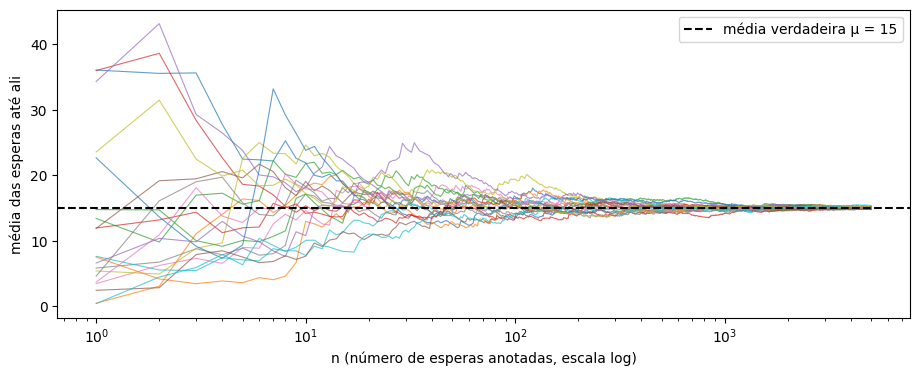

n =    10: médias das 20 pessoas entre  7.65 e 24.65 min (desvio entre elas: 4.73)
n =   100: médias das 20 pessoas entre 13.49 e 19.41 min (desvio entre elas: 1.36)
n =  1000: médias das 20 pessoas entre 14.24 e 15.56 min (desvio entre elas: 0.34)
n =  5000: médias das 20 pessoas entre 14.76 e 15.37 min (desvio entre elas: 0.16)


In [2]:
# Tempos de espera exponenciais com média 15 minutos (notebook 08): 20 "pessoas" anotando 5.000 esperas cada.
mu = 15
esperas = rng.exponential(scale=mu, size=(20, 5_000))
n = np.arange(1, 5_001)
medias_acumuladas = np.cumsum(esperas, axis=1) / n     # a média "até agora" de cada pessoa

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(n, medias_acumuladas.T, linewidth=0.8, alpha=0.7)   # .T (transposta): uma linha do gráfico por pessoa
ax.axhline(mu, color="black", linestyle="--", label="média verdadeira μ = 15")
ax.set_xscale("log")
ax.set_xlabel("n (número de esperas anotadas, escala log)")
ax.set_ylabel("média das esperas até ali")
ax.legend()
plt.show()

for k in [10, 100, 1_000, 5_000]:
    medias_k = medias_acumuladas[:, k - 1]
    print(f"n = {k:>5}: médias das 20 pessoas entre {medias_k.min():5.2f} e {medias_k.max():5.2f} min (desvio entre elas: {medias_k.std():.2f})")

**Conclusão:** as 20 curvas começam espalhadas e vão se juntando em torno de 15. Com **10** esperas, as médias das 20 pessoas vão de **7,65 a 24,65** minutos; com **100**, de 13,49 a 19,41; com **1.000**, de 14,24 a 15,56; e com **5.000**, de **14,76 a 15,37**.

O desvio entre as pessoas também conta uma história: ele cai de 4,73 para 1,36, 0,34 e 0,16. Aumentar a amostra **10 vezes** (de 10 para 100, ou de 100 para 1.000) reduziu a dispersão das médias cerca de **3 vezes**, e não 10. Esse "3" é $\sqrt{10} \approx 3{,}16$, a raiz quadrada que vamos encontrar logo abaixo.

## 2. Quando a LGN falha: a distribuição de Cauchy

A LGN exige que a média $\mu$ **exista**. Parece óbvio, mas há distribuições com caudas tão pesadas que a média não existe. A mais famosa é a **Cauchy**: ela parece um sino, mas produz, de vez em quando, valores **astronomicamente** grandes, que nenhuma quantidade de dados consegue diluir.

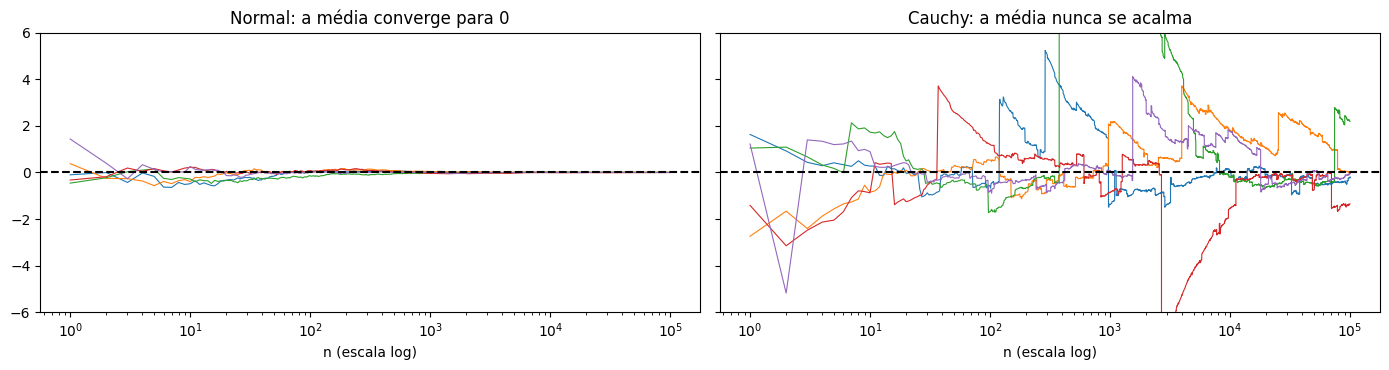

Maior valor absoluto sorteado — normal: 5.1   Cauchy: 236.035


In [3]:
cauchy = rng.standard_cauchy(size=(5, 100_000))
normal = rng.normal(size=(5, 100_000))
n = np.arange(1, 100_001)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
axes[0].plot(n, (np.cumsum(normal, axis=1) / n).T, linewidth=0.8)
axes[0].set_title("Normal: a média converge para 0")
axes[1].plot(n, (np.cumsum(cauchy, axis=1) / n).T, linewidth=0.8)
axes[1].set_title("Cauchy: a média nunca se acalma")
for ax in axes:
    ax.set_xscale("log")
    ax.axhline(0, color="black", linestyle="--")
    ax.set_xlabel("n (escala log)")
axes[0].set_ylim(-6, 6)
plt.tight_layout()
plt.show()

maior_cauchy = f"{np.abs(cauchy).max():_.0f}".replace("_", ".")   # separador de milhares com ponto
print(f"Maior valor absoluto sorteado — normal: {np.abs(normal).max():.1f}   Cauchy: {maior_cauchy}")

**Conclusão:** com a normal (esquerda), as cinco médias se colam no zero antes de 1.000 valores. Com a Cauchy (direita), elas **nunca se acalmam**: de tempos em tempos, um único valor gigante (o maior chegou a **236 mil**, contra **5,1** na normal) dá um "salto" na média, mesmo depois de dezenas de milhares de valores. A média da Cauchy de 100.000 valores não é mais confiável que a de um único valor.

Na prática, dados com caudas extremamente pesadas (perdas financeiras, tamanhos de arquivos, número de seguidores em redes sociais) podem se comportar de forma parecida. Nesses casos, a **mediana** (robusta, notebook 02) é uma escolha muito mais segura que a média.

## 🎓 Conceito: distribuição amostral e erro padrão

Imagine repetir o estudo **muitas vezes**: cada vez, tiramos uma nova amostra de tamanho $n$ e calculamos a média. As médias formam uma distribuição: a **distribuição amostral da média**. É o que fizemos, em pequena escala, com as 5 amostras do notebook 01.

Usando as propriedades do notebook 07 ($\text{Var}(X+Y) = \text{Var}(X) + \text{Var}(Y)$ para independentes, e $\text{Var}(aX) = a^2\,\text{Var}(X)$):

$$E[\bar{X}] = \mu \qquad \text{Var}(\bar{X}) = \frac{\sigma^2}{n} \qquad \text{EP} = \text{desvio de } \bar{X} = \frac{\sigma}{\sqrt{n}}$$

O desvio padrão da distribuição amostral tem um nome especial: **erro padrão** (EP). Ele mede **quanto a média de uma amostra costuma errar**.

A raiz quadrada tem uma consequência prática importante: para **reduzir o erro pela metade**, é preciso **quadruplicar** a amostra. Para reduzi-lo 10 vezes, 100 vezes mais dados.

In [4]:
# Uma população assimétrica: exponencial com média 15 e desvio padrão 15.
sigma = 15
linhas = []
for n_amostra in [5, 20, 80, 320, 1280]:
    # 10.000 estudos, cada um com uma amostra de tamanho n; .mean(axis=1) dá a média de cada estudo.
    medias = rng.exponential(scale=mu, size=(10_000, n_amostra)).mean(axis=1)
    linhas.append({"n": n_amostra,
                   "média das médias": medias.mean(),
                   "desvio das médias (simulado)": medias.std(),
                   "erro padrão σ/√n (teoria)": sigma / np.sqrt(n_amostra)})
pd.DataFrame(linhas).set_index("n")

,média das médias,desvio das médias (simulado),erro padrão σ/√n (teoria)
n,,,
5,14.9612,6.7067,6.7082
20,15.0241,3.3763,3.3541
80,15.0014,1.6603,1.6771
320,14.9935,0.8311,0.8385
1280,14.9999,0.4224,0.4193


**Conclusão:** a média das médias fica sempre perto de **15**, o valor verdadeiro: a média da amostra **não erra sistematicamente** para nenhum lado. E o desvio das médias simuladas bate com a fórmula $\sigma/\sqrt{n}$ em todos os tamanhos: **6,71** contra 6,71 com $n = 5$; **0,42** contra 0,42 com $n = 1.280$.

Cada linha da tabela tem uma amostra **4 vezes maior** que a anterior, e o erro padrão cai **pela metade** a cada linha (6,71 → 3,38 → 1,66 → 0,83 → 0,42). Para ganhar precisão, dados extras rendem cada vez menos.

## 🎓 Conceito: Teorema Central do Limite

O TCL diz algo ainda mais forte sobre a distribuição amostral: quando $n$ é grande, a média $\bar{X}$ tem distribuição **aproximadamente normal**:

$$\bar{X} \approx N\left(\mu, \frac{\sigma^2}{n}\right)$$

**qualquer que seja** a distribuição original dos dados (desde que ela tenha média e variância finitas, o que exclui a Cauchy). Os dados podem ser assimétricos, discretos, bimodais: a **média** deles fica com cara de sino.

É por isso que a normal aparece em todo lugar: muitas grandezas da natureza são **somas** de muitos pequenos efeitos independentes (a altura de uma pessoa depende de muitos genes e fatores ambientais), e o TCL faz essas somas ficarem normais.

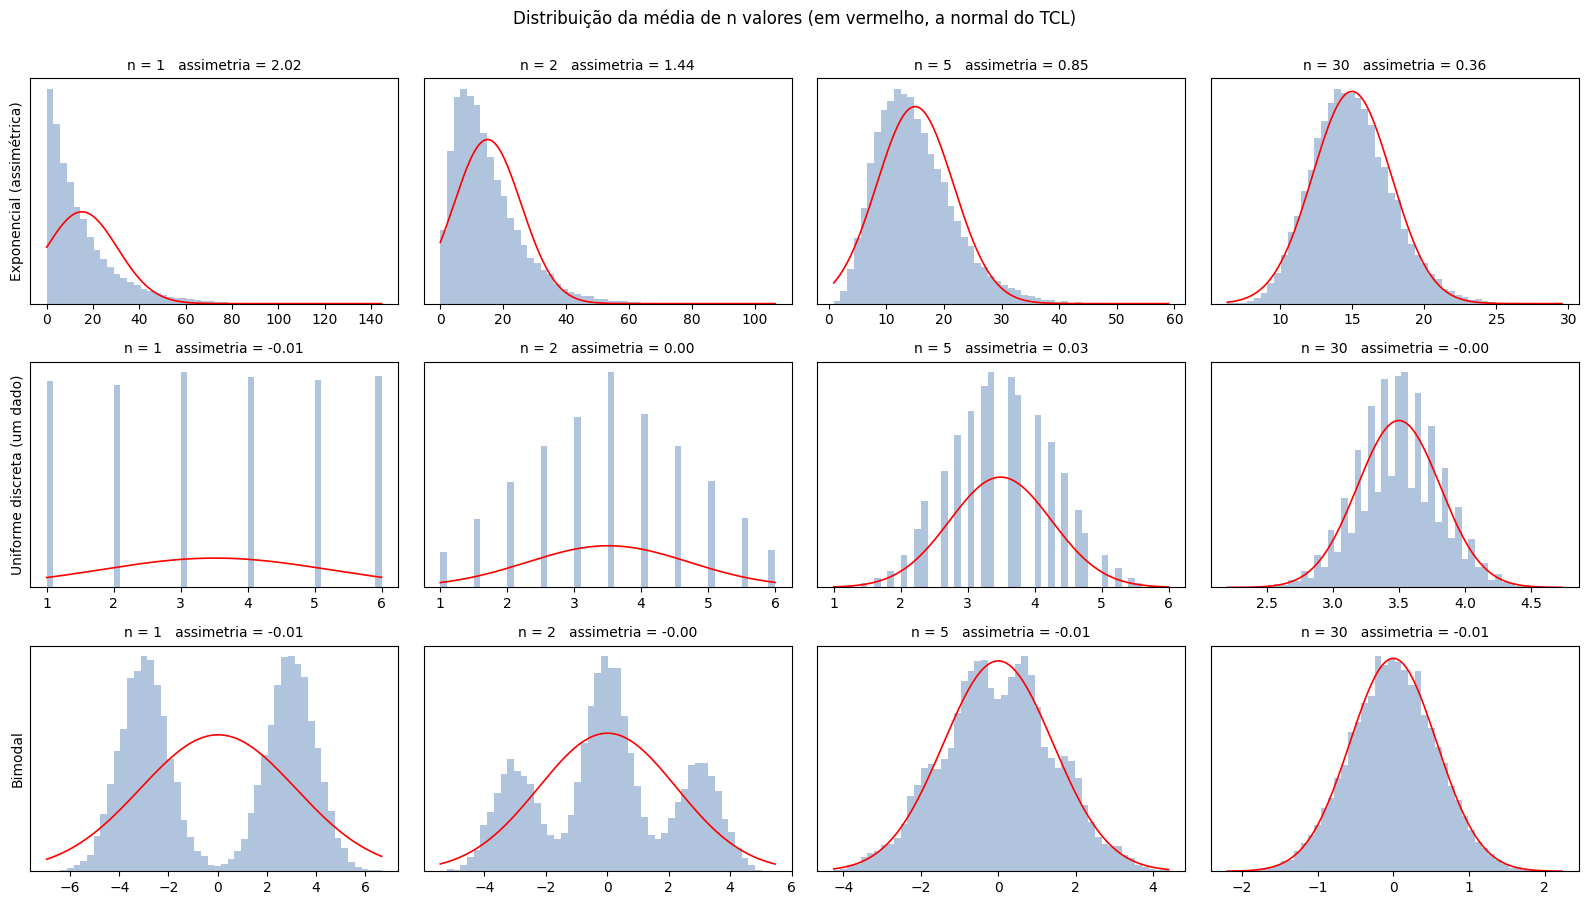

In [5]:
# Três populações bem diferentes da normal.
populacoes = {
    "Exponencial (assimétrica)": lambda tamanho: rng.exponential(15, tamanho),   # lambda cria uma função curta "em linha"
    "Uniforme discreta (um dado)": lambda tamanho: rng.integers(1, 7, tamanho),
    "Bimodal": lambda tamanho: np.where(rng.random(tamanho) < 0.5, rng.normal(-3, 1, tamanho), rng.normal(3, 1, tamanho)),
}
tamanhos = [1, 2, 5, 30]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for i, (nome, sortear) in enumerate(populacoes.items()):   # enumerate devolve (posição, item)
    for j, n_amostra in enumerate(tamanhos):
        medias = sortear((20_000, n_amostra)).mean(axis=1)
        ax = axes[i, j]
        ax.hist(medias, bins=50, density=True, color="lightsteelblue")
        # A normal prevista pelo TCL, com a média e o erro padrão das próprias médias.
        eixo = np.linspace(medias.min(), medias.max(), 200)
        ax.plot(eixo, stats.norm.pdf(eixo, medias.mean(), medias.std()), color="red", linewidth=1.2)
        ax.set_title(f"n = {n_amostra}   assimetria = {stats.skew(medias):.2f}", fontsize=10)
        ax.set_yticks([])
    axes[i, 0].set_ylabel(nome, fontsize=10)
plt.suptitle("Distribuição da média de n valores (em vermelho, a normal do TCL)", y=1.0)
plt.tight_layout()
plt.show()

**Conclusão:** o TCL em ação:
- **Exponencial (1ª linha):** com $n = 1$ é a própria exponencial (assimetria **2,02**). A assimetria cai para 1,44 com $n = 2$, 0,85 com $n = 5$ e **0,36** com $n = 30$, quando o histograma já coincide com a normal vermelha.
- **Dado (2ª linha):** a uniforme discreta vira um triângulo com $n = 2$ (a soma de dois dados do notebook 07) e já parece um sino com $n = 5$. (O histograma de $n = 30$ tem "dentes" só porque as médias de 30 dados são múltiplos de 1/30 e não se encaixam bem nas faixas do gráfico.)
- **Bimodal (3ª linha):** os dois picos dão lugar a **três** picos com $n = 2$ (as duas pessoas do mesmo morro ou uma de cada) e, com $n = 5$, a um único sino.

Repare que o eixo x também **encolhe** da esquerda para a direita: as médias ficam cada vez mais concentradas, com a largura $\sigma/\sqrt{n}$.

## 3. Aplicação: a aproximação normal da binomial

Uma variável binomial é a **soma** de $n$ Bernoullis (notebook 07). Pelo TCL, para $n$ grande ela é aproximadamente normal, com média $np$ e desvio $\sqrt{np(1-p)}$. E a **proporção** de sucessos $\hat{p} = X/n$ (uma média de zeros e uns) tem erro padrão:

$$\text{EP}(\hat{p}) = \sqrt{\frac{p(1-p)}{n}}$$

Voltando ao classificador do notebook 07, com acurácia verdadeira de 85%: qual o erro padrão da acurácia medida num conjunto de teste de tamanho $n$?

In [6]:
p = 0.85
linhas = []
for n_teste in [100, 1_000, 10_000]:
    ep = np.sqrt(p * (1 - p) / n_teste)
    exata = stats.binom(n_teste, p)
    linhas.append({
        "tamanho do teste": n_teste,
        "erro padrão": ep,
        # Intervalo de 95% pela normal: média ± 1,96 erros padrão (1,96 é o quantil 0,975 da normal padrão).
        "95% (normal)": f"{p - 1.96 * ep:.1%} a {p + 1.96 * ep:.1%}",
        "95% (binomial exata)": f"{exata.ppf(0.025) / n_teste:.1%} a {exata.ppf(0.975) / n_teste:.1%}",
    })
print(f"Quantil 0,975 da normal padrão: {stats.norm.ppf(0.975):.4f}")
pd.DataFrame(linhas).set_index("tamanho do teste")

Quantil 0,975 da normal padrão: 1.9600


,erro padrão,95% (normal),95% (binomial exata)
tamanho do teste,,,
100,0.0357,78.0% a 92.0%,78.0% a 92.0%
1000,0.0113,82.8% a 87.2%,82.8% a 87.2%
10000,0.0036,84.3% a 85.7%,84.3% a 85.7%


**Conclusão:** os intervalos pela aproximação normal ($p \pm 1{,}96$ erros padrão) coincidem com os da binomial exata nos três tamanhos (com uma casa decimal). Com **100** exemplos de teste, a acurácia medida pode ficar em qualquer lugar entre **78% e 92%**; com **1.000**, entre 82,8% e 87,2%; com **10.000**, entre **84,3% e 85,7%**, com erro padrão de 0,36 ponto.

O 1,96 que aparece aqui (o quantil 0,975 da normal) será o protagonista dos **intervalos de confiança** no próximo notebook.

## 4. Quando o TCL demora: caudas pesadas

O TCL é um resultado **assintótico**: vale quando $n$ é "grande o bastante". A regra informal "$n \ge 30$" funciona para distribuições razoavelmente comportadas, mas **não** para as muito assimétricas. Vamos medir a assimetria das médias de amostras de uma **log-normal** com cauda pesada (parecida com rendas ou com o preço de imóveis).

In [7]:
linhas = []
for n_amostra in [30, 100, 1_000]:
    medias_exp = rng.exponential(1, size=(10_000, n_amostra)).mean(axis=1)
    medias_lognormal = rng.lognormal(0, 1.5, size=(10_000, n_amostra)).mean(axis=1)
    linhas.append({"n": n_amostra,
                   "assimetria das médias (exponencial)": stats.skew(medias_exp),
                   "assimetria das médias (log-normal σ=1,5)": stats.skew(medias_lognormal)})
pd.DataFrame(linhas).set_index("n")

,assimetria das médias (exponencial),"assimetria das médias (log-normal σ=1,5)"
n,,
30,0.3901,3.7631
100,0.1974,2.0277
1000,0.0243,0.8493


**Conclusão:** para a **exponencial**, a assimetria das médias com $n = 30$ já é pequena (**0,39**) e quase desaparece com $n = 1.000$ (0,02). Para a **log-normal com cauda pesada**, as médias de 30 valores ainda são **muito** assimétricas (**3,76**, mais que a própria exponencial!), e mesmo com 1.000 valores a assimetria é **0,85**, longe do sino.

A regra "$n \ge 30$ basta" **não vale** para dados com caudas pesadas. Com rendas, preços ou tempos muito assimétricos, vale a pena transformar os dados (o log do notebook 03), usar a mediana ou estimar a incerteza com o **bootstrap** (notebook 11), que não depende da normalidade.

## 5. Resumo e próximos passos

| | O que diz | Exige |
|---|---|---|
| **LGN** | $\bar{X}_n \to \mu$ quando $n$ cresce | valores independentes, média finita |
| **Erro padrão** | o desvio de $\bar{X}$ é $\sigma / \sqrt{n}$ | valores independentes |
| **TCL** | $\bar{X} \approx N(\mu, \sigma^2/n)$ para $n$ grande | média e variância finitas; $n$ "grande" depende das caudas |

**Conceitos que você aprendeu**
- A **Lei dos Grandes Números** e o caso da **Cauchy**, em que ela falha.
- A **distribuição amostral** da média e o **erro padrão** $\sigma / \sqrt{n}$: 4 vezes mais dados para metade do erro.
- O **Teorema Central do Limite**, que transforma médias de quase qualquer distribuição em sinos.
- A **aproximação normal** da binomial e o erro padrão de uma proporção.
- O TCL pode **demorar** muito com caudas pesadas.

🔗 **Ponte para o ML:**
- A média das 5 dobras da validação cruzada (ML-01 e ML-02) é uma média, e o desvio entre as dobras dá uma ideia da sua incerteza.
- Um conjunto de teste com 10.000 exemplos mede a acurácia com erro padrão de ~0,4 ponto; com 100 exemplos, ~3,6 pontos.
- O **bagging** e a random forest tiram proveito da mesma ideia: a **média** de muitas árvores varia menos que uma árvore sozinha.

**Python novo:** `.T` (transposta), `rng.standard_cauchy`, `lambda`, `enumerate`, `plt.suptitle`, `ax.set_yticks([])`, matrizes de subgráficos `axes[i, j]`.

**Próximo notebook:** o erro padrão $\sigma/\sqrt{n}$ depende do $\sigma$ da **população**, que não conhecemos. No notebook 11 vamos estimá-lo a partir da própria amostra, construir **intervalos de confiança** e conhecer o **bootstrap**, uma técnica que estima a incerteza de **qualquer** estatística apenas reamostrando os dados.